# CMP Exploratory Data Analysis and Cleaning

## Project: AstroHealth — Astronaut Biomarker Analytics

### Objective
This notebook focuses on exploring and validating the Comprehensive Metabolic Panel (CMP) dataset associated with NASA's Inspiration4 astronaut health research data.

The objective is to understand the dataset structure, identify the available biomarkers, inspect measurement units and missing values, examine participant and time-point coverage, and assess the suitability of the data for participant-specific baseline analysis.

### Planned Workflow
1. Load and inspect the CMP dataset.
2. Understand the dataset structure, columns, and data types.
3. Examine participants, biomarkers, measurement units, and time points.
4. Assess missing values and measurement coverage.
5. Review existing transformations and validate data quality.
6. Investigate preflight baseline availability.
7. Document findings and prepare for integration with the CBC dataset.

**Scope:** This notebook covers exploratory analysis and data validation. Final cleaning rules, anomaly-scoring methods, and pipeline implementation will be established after the dataset has been examined.

In [ ]:
import pandas as pd

cmp = pd.read_csv(
    "/content/LSDS-8_Comprehensive_Metabolic_Panel_CMP_TRANSFORMED.csv"
)

In [ ]:
df = cmp.copy()

In [ ]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())


Dataset shape: (28, 58)

Column names:
['Sample Name', 'albumin_value_gram_per_deciliter', 'albumin_range_min_gram_per_deciliter', 'albumin_range_max_gram_per_deciliter', 'albumin_to_globulin_ratio_value', 'albumin_to_globulin_ratio_range_min', 'albumin_to_globulin_ratio_range_max', 'alkaline_phosphatase_value_units_per_liter', 'alkaline_phosphatase_range_min_units_per_liter', 'alkaline_phosphatase_range_max_units_per_liter', 'alt_value_units_per_liter', 'alt_range_min_units_per_liter', 'alt_max_units_per_liter', 'ast_value_units_per_liter', 'ast_range_min_units_per_liter', 'ast_max_units_per_liter', 'total_bilirubin_value_milligram_per_deciliter', 'total_bilirubin_range_min_milligram_per_deciliter', 'total_bilirubin_range_max_milligram_per_deciliter', 'bun_to_creatinine_ratio_value', 'bun_to_creatinine_ratio_range_min', 'bun_to_creatinine_ratio_range_max', 'calcium_value_milligram_per_deciliter', 'calcium_range_min_milligram_per_deciliter', 'calcium_range_max_milligram_per_deciliter',

,Sample Name,albumin_value_gram_per_deciliter,albumin_range_min_gram_per_deciliter,albumin_range_max_gram_per_deciliter,albumin_to_globulin_ratio_value,albumin_to_globulin_ratio_range_min,albumin_to_globulin_ratio_range_max,alkaline_phosphatase_value_units_per_liter,alkaline_phosphatase_range_min_units_per_liter,alkaline_phosphatase_range_max_units_per_liter,...,potassium_range_max_millimol_per_liter,total_protein_value_gram_per_deciliter,total_protein_range_min_gram_per_deciliter,total_protein_range_max_gram_per_deciliter,sodium_value_millimol_per_liter,sodium_range_min_millimol_per_liter,sodium_range_max_millimol_per_liter,urea_nitrogen_bun_value_milligram_per_deciliter,urea_nitrogen_bun_range_min_milligram_per_deciliter,urea_nitrogen_bun_range_max_milligram_per_deciliter
0,C001_serum_L-3,4.9,3.6,5.1,2.0,1,2.5,45,36,130,...,5.3,7.4,6.1,8.1,142,135,146,20,7,25
1,C001_serum_L-44,5.0,3.6,5.1,1.9,1,2.5,46,36,130,...,5.3,7.7,6.1,8.1,139,135,146,19,7,25
2,C001_serum_L-92,5.0,3.6,5.1,2.2,1,2.5,51,36,130,...,5.3,7.3,6.1,8.1,141,135,146,25,7,25
3,C001_serum_R+1,4.9,3.6,5.1,1.9,1,2.5,52,36,130,...,5.3,7.5,6.1,8.1,138,135,146,18,7,25
4,C001_serum_R+194,4.6,3.6,5.1,1.9,1,2.5,50,36,130,...,5.3,7.0,6.1,8.1,137,135,146,28,7,25


In [ ]:
print("\nData types:")
print(df.dtypes)

print("\nMissing values per column:")
display(df.isna().sum().sort_values(ascending=False))


Data types:
Sample Name                                                                          object
albumin_value_gram_per_deciliter                                                    float64
albumin_range_min_gram_per_deciliter                                                float64
albumin_range_max_gram_per_deciliter                                                float64
albumin_to_globulin_ratio_value                                                     float64
albumin_to_globulin_ratio_range_min                                                   int64
albumin_to_globulin_ratio_range_max                                                 float64
alkaline_phosphatase_value_units_per_liter                                            int64
alkaline_phosphatase_range_min_units_per_liter                                        int64
alkaline_phosphatase_range_max_units_per_liter                                        int64
alt_value_units_per_liter                                          

,0
egfr_african_american_range_max_milliliter_per_minute_per_1.73_meter_squared,28
egfr_non_african_american_range_max_milliliter_per_minute_per_1.73_meter_squared,28
bun_to_creatinine_ratio_value,22
bun_to_creatinine_ratio_range_min,1
bun_to_creatinine_ratio_range_max,1
total_bilirubin_value_milligram_per_deciliter,1
albumin_range_min_gram_per_deciliter,0
albumin_range_max_gram_per_deciliter,0
albumin_to_globulin_ratio_value,0
albumin_to_globulin_ratio_range_min,0


In [ ]:
# Extract participant ID, sample type, and time point
sample_parts = df["Sample Name"].str.extract(
    r"^(C\d+)_([^_]+)_(L-\d+|R\+\d+)$"
)
df["SUBJECT_ID"] = sample_parts[0]
df["SAMPLE_TYPE"] = sample_parts[1]
df["TEST_DATE"] = sample_parts[2]

print("Unparsed sample names:")
display(df.loc[
    df["SUBJECT_ID"].isna(),
    ["Sample Name"]
])

print("\nParticipants:")
print(sorted(df["SUBJECT_ID"].dropna().unique()))

print("\nTime-point coverage:")
display(
    df.groupby(["SUBJECT_ID", "TEST_DATE"])
       .size()
       .unstack(fill_value=0)
)

print("\nDuplicate sample names:")
display(df[df["Sample Name"].duplicated(keep=False)])

Unparsed sample names:


,Sample Name



Participants:
['C001', 'C002', 'C003', 'C004']

Time-point coverage:


TEST_DATE,L-3,L-44,L-92,R+1,R+194,R+45,R+82
SUBJECT_ID,,,,,,,
C001,1,1,1,1,1,1,1
C002,1,1,1,1,1,1,1
C003,1,1,1,1,1,1,1
C004,1,1,1,1,1,1,1



Duplicate sample names:


,Sample Name,albumin_value_gram_per_deciliter,albumin_range_min_gram_per_deciliter,albumin_range_max_gram_per_deciliter,albumin_to_globulin_ratio_value,albumin_to_globulin_ratio_range_min,albumin_to_globulin_ratio_range_max,alkaline_phosphatase_value_units_per_liter,alkaline_phosphatase_range_min_units_per_liter,alkaline_phosphatase_range_max_units_per_liter,...,total_protein_range_max_gram_per_deciliter,sodium_value_millimol_per_liter,sodium_range_min_millimol_per_liter,sodium_range_max_millimol_per_liter,urea_nitrogen_bun_value_milligram_per_deciliter,urea_nitrogen_bun_range_min_milligram_per_deciliter,urea_nitrogen_bun_range_max_milligram_per_deciliter,SUBJECT_ID,SAMPLE_TYPE,TEST_DATE


In [ ]:
for col in df.columns:
    print(col)

Sample Name
albumin_value_gram_per_deciliter
albumin_range_min_gram_per_deciliter
albumin_range_max_gram_per_deciliter
albumin_to_globulin_ratio_value
albumin_to_globulin_ratio_range_min
albumin_to_globulin_ratio_range_max
alkaline_phosphatase_value_units_per_liter
alkaline_phosphatase_range_min_units_per_liter
alkaline_phosphatase_range_max_units_per_liter
alt_value_units_per_liter
alt_range_min_units_per_liter
alt_max_units_per_liter
ast_value_units_per_liter
ast_range_min_units_per_liter
ast_max_units_per_liter
total_bilirubin_value_milligram_per_deciliter
total_bilirubin_range_min_milligram_per_deciliter
total_bilirubin_range_max_milligram_per_deciliter
bun_to_creatinine_ratio_value
bun_to_creatinine_ratio_range_min
bun_to_creatinine_ratio_range_max
calcium_value_milligram_per_deciliter
calcium_range_min_milligram_per_deciliter
calcium_range_max_milligram_per_deciliter
carbon_dioxide_value_millimol_per_liter
carbon_dioxide_range_min_millimol_per_liter
carbon_dioxide_range_max_milli

In [ ]:
missing_summary = (
    df.isna()
      .sum()
      .loc[lambda counts: counts > 0]
      .sort_values(ascending=False)
)

display(missing_summary)

,0
egfr_african_american_range_max_milliliter_per_minute_per_1.73_meter_squared,28
egfr_non_african_american_range_max_milliliter_per_minute_per_1.73_meter_squared,28
bun_to_creatinine_ratio_value,22
total_bilirubin_value_milligram_per_deciliter,1
bun_to_creatinine_ratio_range_max,1
bun_to_creatinine_ratio_range_min,1


In [ ]:
egfr_cols = [
    col for col in df.columns
    if col.startswith("egfr_")
]

display(df[["Sample Name"] + egfr_cols])

,Sample Name,egfr_african_american_value_milliliter_per_minute_per_1.73_meter_squared,egfr_african_american_range_min_milliliter_per_minute_per_1.73_meter_squared,egfr_african_american_range_max_milliliter_per_minute_per_1.73_meter_squared,egfr_non_african_american_value_milliliter_per_minute_per_1.73_meter_squared,egfr_non_african_american_range_min_milliliter_per_minute_per_1.73_meter_squared,egfr_non_african_american_range_max_milliliter_per_minute_per_1.73_meter_squared
0,C001_serum_L-3,75,60,NaN,65,60,NaN
1,C001_serum_L-44,98,60,NaN,85,60,NaN
2,C001_serum_L-92,85,60,NaN,73,60,NaN
3,C001_serum_R+1,96,60,NaN,83,60,NaN
4,C001_serum_R+194,80,60,NaN,69,60,NaN
5,C001_serum_R+45,97,60,NaN,84,60,NaN
6,C001_serum_R+82,84,60,NaN,73,60,NaN
7,C002_serum_L-3,79,60,NaN,68,60,NaN
8,C002_serum_L-44,88,60,NaN,76,60,NaN
9,C002_serum_L-92,95,60,NaN,82,60,NaN


In [ ]:
bun_cols = [
    col for col in df.columns
    if col.startswith("bun_to_creatinine_ratio")
]

display(df[["Sample Name"] + bun_cols])

,Sample Name,bun_to_creatinine_ratio_value,bun_to_creatinine_ratio_range_min,bun_to_creatinine_ratio_range_max
0,C001_serum_L-3,15.0,6.0,22.0
1,C001_serum_L-44,NaN,6.0,22.0
2,C001_serum_L-92,NaN,6.0,22.0
3,C001_serum_R+1,NaN,6.0,22.0
4,C001_serum_R+194,22.0,6.0,22.0
5,C001_serum_R+45,NaN,6.0,22.0
6,C001_serum_R+82,NaN,6.0,22.0
7,C002_serum_L-3,NaN,6.0,22.0
8,C002_serum_L-44,NaN,6.0,22.0
9,C002_serum_L-92,NaN,6.0,22.0


In [ ]:
# Create a separate analysis copy
cmp_analysis = df.copy()


# Identify race-labelled eGFR columns and exclude them from this analysis
egfr_cols = [
    col for col in cmp_analysis.columns
    if col.startswith("egfr_african_american_")
    or col.startswith("egfr_non_african_american_")
]

# Exclude BUN-to-creatinine ratio from baseline anomaly scoring
bun_ratio_cols = [
    col for col in cmp_analysis.columns
    if col.startswith("bun_to_creatinine_ratio_")
]

cmp_analysis = cmp_analysis.drop(
    columns=egfr_cols + bun_ratio_cols
)

# Standardize ALT/AST maximum-range column names
cmp_analysis = cmp_analysis.rename(columns={
    "alt_max_units_per_liter": "alt_range_max_units_per_liter",
    "ast_max_units_per_liter": "ast_range_max_units_per_liter"
})

print("Original working DataFrame shape:", df.shape)
print("Analysis DataFrame shape:", cmp_analysis.shape)

print("\nExcluded eGFR columns:", len(egfr_cols))
print("Excluded BUN-to-creatinine ratio columns:", len(bun_ratio_cols))

print("\nRemaining missing values:")
display(
    cmp_analysis.isna()
        .sum()
        .loc[lambda counts: counts > 0]
        .sort_values(ascending=False)
)


Original working DataFrame shape: (28, 61)
Analysis DataFrame shape: (28, 52)

Excluded eGFR columns: 6
Excluded BUN-to-creatinine ratio columns: 3

Remaining missing values:


,0
total_bilirubin_value_milligram_per_deciliter,1


In [ ]:
# Define the preflight time points
preflight_points = ["L-92", "L-44", "L-3"]

# Select preflight samples
cmp_preflight = cmp_analysis[
    cmp_analysis["TEST_DATE"].isin(preflight_points)
].copy()

print("Preflight shape:", cmp_preflight.shape)

print("\nPreflight sample count per participant:")
display(
    cmp_preflight.groupby("SUBJECT_ID")["Sample Name"]
    .count()
)

# Identify biomarker measurement columns
value_cols = [
    col for col in cmp_analysis.columns
    if "_value_" in col or col.endswith("_value")
]

print("\nBiomarker value columns:", len(value_cols))
print(value_cols)


Preflight shape: (12, 52)

Preflight sample count per participant:


,Sample Name
SUBJECT_ID,
C001,3
C002,3
C003,3
C004,3



Biomarker value columns: 16
['albumin_value_gram_per_deciliter', 'albumin_to_globulin_ratio_value', 'alkaline_phosphatase_value_units_per_liter', 'alt_value_units_per_liter', 'ast_value_units_per_liter', 'total_bilirubin_value_milligram_per_deciliter', 'calcium_value_milligram_per_deciliter', 'carbon_dioxide_value_millimol_per_liter', 'chloride_value_millimol_per_liter', 'creatinine_value_milligram_per_deciliter', 'globulin_value_gram_per_deciliter', 'glucose_value_milligram_per_deciliter', 'potassium_value_millimol_per_liter', 'total_protein_value_gram_per_deciliter', 'sodium_value_millimol_per_liter', 'urea_nitrogen_bun_value_milligram_per_deciliter']


In [ ]:

# Calculate baseline statistics for each participant and biomarker
cmp_baseline_stats = (
    cmp_preflight
    .groupby("SUBJECT_ID")[value_cols]
    .agg(["count", "mean", "std"])
)

display(cmp_baseline_stats)


albumin_value_gram_per_deciliter                      \
                                      count      mean       std   
SUBJECT_ID                                                        
C001                                      3  4.966667  0.057735   
C002                                      3  4.600000  0.300000   
C003                                      3  4.500000  0.360555   
C004                                      3  4.533333  0.115470   

           albumin_to_globulin_ratio_value                      \
                                     count      mean       std   
SUBJECT_ID                                                       
C001                                     3  2.033333  0.152753   
C002                                     3  1.566667  0.057735   
C003                                     3  1.500000  0.173205   
C004                                     3  1.600000  0.100000   

           alkaline_phosphatase_value_units_per_liter                       \
                                                count       mean       std   
SUBJECT_ID                                                                   
C001                                                3  47.333333  3.214550   
C002                                                3  73.000000  5.000000   
C003                                                3  35.000000  5.291503   
C004                                                3  56.333333  1.527525   

           alt_value_units_per_liter  ... potassium_value_millimol_per_liter  \
                               count  ...                                std   
SUBJECT_ID                            ...                                      
C001                               3  ...                           0.351188   
C002                               3  ...                           0.100000   
C003                               3  ...                           0.200000   
C004                               3  ...                           0.288675   

           total_protein_value_gram_per_deciliter                      \
                                            count      mean       std   
SUBJECT_ID                                                              
C001                                            3  7.466667  0.208167   
C002                                            3  7.500000  0.458258   
C003                                            3  7.566667  1.078579   
C004                                            3  7.333333  0.057735   

           sodium_value_millimol_per_liter                        \
                                     count        mean       std   
SUBJECT_ID                                                         
C001                                     3  140.666667  1.527525   
C002                                     3  142.000000  1.000000   
C003                                     3  138.666667  0.577350   
C004                                     3  139.666667  1.527525   

           urea_nitrogen_bun_value_milligram_per_deciliter             \
                                                     count       mean   
SUBJECT_ID                                                              
C001                                                     3  21.333333   
C002                                                     3  15.666667   
C003                                                     3  20.666667   
C004                                                     3  20.000000   

                      
                 std  
SUBJECT_ID            
C001        3.214550  
C002        1.527525  
C003        4.725816  
C004        1.732051  

[4 rows x 48 columns]

In [ ]:

# Extract the count statistics from the multi-level columns
baseline_counts = cmp_baseline_stats.xs(
    "count", axis=1, level=1
)

print("Baseline observation counts:")
display(baseline_counts)

print("\nCounts below 3:")
display(baseline_counts[baseline_counts < 3])


Baseline observation counts:


,albumin_value_gram_per_deciliter,albumin_to_globulin_ratio_value,alkaline_phosphatase_value_units_per_liter,alt_value_units_per_liter,ast_value_units_per_liter,total_bilirubin_value_milligram_per_deciliter,calcium_value_milligram_per_deciliter,carbon_dioxide_value_millimol_per_liter,chloride_value_millimol_per_liter,creatinine_value_milligram_per_deciliter,globulin_value_gram_per_deciliter,glucose_value_milligram_per_deciliter,potassium_value_millimol_per_liter,total_protein_value_gram_per_deciliter,sodium_value_millimol_per_liter,urea_nitrogen_bun_value_milligram_per_deciliter
SUBJECT_ID,,,,,,,,,,,,,,,,
C001,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3
C002,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3
C003,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3
C004,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3,3



Counts below 3:


,albumin_value_gram_per_deciliter,albumin_to_globulin_ratio_value,alkaline_phosphatase_value_units_per_liter,alt_value_units_per_liter,ast_value_units_per_liter,total_bilirubin_value_milligram_per_deciliter,calcium_value_milligram_per_deciliter,carbon_dioxide_value_millimol_per_liter,chloride_value_millimol_per_liter,creatinine_value_milligram_per_deciliter,globulin_value_gram_per_deciliter,glucose_value_milligram_per_deciliter,potassium_value_millimol_per_liter,total_protein_value_gram_per_deciliter,sodium_value_millimol_per_liter,urea_nitrogen_bun_value_milligram_per_deciliter
SUBJECT_ID,,,,,,,,,,,,,,,,
C001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
C002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
C003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
C004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:

baseline_std = cmp_baseline_stats.xs(
    "std", axis=1, level=1
)

print("Zero standard deviations:")
display(baseline_std.where(baseline_std == 0).dropna(
    axis=1, how="all"
))

print("\nMissing standard deviations:")
display(baseline_std.isna().sum())


Zero standard deviations:


""
SUBJECT_ID
C001
C002
C003
C004



Missing standard deviations:


,0
albumin_value_gram_per_deciliter,0
albumin_to_globulin_ratio_value,0
alkaline_phosphatase_value_units_per_liter,0
alt_value_units_per_liter,0
ast_value_units_per_liter,0
total_bilirubin_value_milligram_per_deciliter,0
calcium_value_milligram_per_deciliter,0
carbon_dioxide_value_millimol_per_liter,0
chloride_value_millimol_per_liter,0
creatinine_value_milligram_per_deciliter,0


In [ ]:

# Separate postflight samples
postflight_points = ["R+1", "R+45", "R+82", "R+194"]

cmp_postflight = cmp_analysis[
    cmp_analysis["TEST_DATE"].isin(postflight_points)
].copy()

# Convert the baseline summary into one row per participant and biomarker
baseline_long = (
    cmp_preflight
    .melt(
        id_vars="SUBJECT_ID",
        value_vars=value_cols,
        var_name="ANALYTE",
        value_name="baseline_value"
    )
    .groupby(["SUBJECT_ID", "ANALYTE"])["baseline_value"]
    .agg(
        baseline_count="count",
        baseline_mean="mean",
        baseline_std="std"
    )
    .reset_index()
)

# Convert postflight measurements to long format
postflight_long = cmp_postflight.melt(
    id_vars=["Sample Name", "SUBJECT_ID", "TEST_DATE"],
    value_vars=value_cols,
    var_name="ANALYTE",
    value_name="observed_value"
)

# Join each postflight measurement to that person's baseline
cmp_scores = postflight_long.merge(
    baseline_long,
    on=["SUBJECT_ID", "ANALYTE"],
    how="left"
)

# Calculate exploratory baseline-relative z-scores
cmp_scores["z_score"] = (
    (cmp_scores["observed_value"] - cmp_scores["baseline_mean"])
    / cmp_scores["baseline_std"]
)

# Mark exploratory deviations for review
cmp_scores["exploratory_flag"] = (
    cmp_scores["z_score"].abs() > 2
)

display(cmp_scores.head(10))


,Sample Name,SUBJECT_ID,TEST_DATE,ANALYTE,observed_value,baseline_count,baseline_mean,baseline_std,z_score,exploratory_flag
0,C001_serum_R+1,C001,R+1,albumin_value_gram_per_deciliter,4.9,3,4.966667,0.057735,-1.154701,False
1,C001_serum_R+194,C001,R+194,albumin_value_gram_per_deciliter,4.6,3,4.966667,0.057735,-6.350853,True
2,C001_serum_R+45,C001,R+45,albumin_value_gram_per_deciliter,4.9,3,4.966667,0.057735,-1.154701,False
3,C001_serum_R+82,C001,R+82,albumin_value_gram_per_deciliter,5.1,3,4.966667,0.057735,2.309401,True
4,C002_serum_R+1,C002,R+1,albumin_value_gram_per_deciliter,4.4,3,4.600000,0.300000,-0.666667,False
5,C002_serum_R+194,C002,R+194,albumin_value_gram_per_deciliter,4.3,3,4.600000,0.300000,-1.000000,False
6,C002_serum_R+45,C002,R+45,albumin_value_gram_per_deciliter,4.2,3,4.600000,0.300000,-1.333333,False
7,C002_serum_R+82,C002,R+82,albumin_value_gram_per_deciliter,4.5,3,4.600000,0.300000,-0.333333,False
8,C003_serum_R+1,C003,R+1,albumin_value_gram_per_deciliter,4.2,3,4.500000,0.360555,-0.832050,False
9,C003_serum_R+194,C003,R+194,albumin_value_gram_per_deciliter,4.4,3,4.500000,0.360555,-0.277350,False


In [ ]:
# Count exploratory flags
print("Total postflight measurements:", len(cmp_scores))
print(
    "Missing observed measurements:",
    cmp_scores["observed_value"].isna().sum()
)
print(
    "Exploratory flags:",
    cmp_scores["exploratory_flag"].sum()
)

# Show all flagged observations
flagged_scores = (
    cmp_scores.loc[
        cmp_scores["exploratory_flag"],
        [
            "Sample Name",
            "SUBJECT_ID",
            "TEST_DATE",
            "ANALYTE",
            "observed_value",
            "baseline_mean",
            "baseline_std",
            "z_score"
        ]
    ]
    .sort_values("z_score", key=lambda s: s.abs(), ascending=False)
)

display(flagged_scores)


Total postflight measurements: 256
Missing observed measurements: 1
Exploratory flags: 63


,Sample Name,SUBJECT_ID,TEST_DATE,ANALYTE,observed_value,baseline_mean,baseline_std,z_score
63,C004_serum_R+82,C004,R+82,alt_value_units_per_liter,23.0,36.333333,1.154701,-11.547005
56,C003_serum_R+1,C003,R+1,alt_value_units_per_liter,19.0,12.666667,0.577350,10.969655
125,C004_serum_R+194,C004,R+194,carbon_dioxide_value_millimol_per_liter,19.0,23.666667,0.577350,-8.082904
58,C003_serum_R+45,C003,R+45,alt_value_units_per_liter,17.0,12.666667,0.577350,7.505553
206,C004_serum_R+45,C004,R+45,potassium_value_millimol_per_liter,5.9,4.033333,0.288675,6.466323
...,...,...,...,...,...,...,...,...
241,C001_serum_R+194,C001,R+194,urea_nitrogen_bun_value_milligram_per_deciliter,28.0,21.333333,3.214550,2.073903
76,C004_serum_R+1,C004,R+1,ast_value_units_per_liter,48.0,39.666667,4.041452,2.061965
13,C004_serum_R+194,C004,R+194,albumin_value_gram_per_deciliter,4.3,4.533333,0.115470,-2.020726
92,C004_serum_R+1,C004,R+1,total_bilirubin_value_milligram_per_deciliter,0.4,0.633333,0.115470,-2.020726


In [ ]:
cmp_scores["exploratory_flag"] = cmp_scores["z_score"].abs() > 2

In [ ]:
# Check whether every flagged row meets the strict threshold
flag_check = cmp_scores.loc[
    cmp_scores["exploratory_flag"],
    ["ANALYTE", "z_score"]
]

print("Flagged rows at or below |z| = 2:",
      (flag_check["z_score"].abs() <= 2).sum())

# Check missing measurements separately
print("Rows with missing z-scores:",
      cmp_scores["z_score"].isna().sum())

Flagged rows at or below |z| = 2: 0
Rows with missing z-scores: 1


In [ ]:
# 1. How many flags occur for each biomarker?
flags_by_analyte = (
    cmp_scores.groupby("ANALYTE")["exploratory_flag"]
    .agg(total_flags="sum", total_rows="count")
    .sort_values("total_flags", ascending=False)
)

display(flags_by_analyte)

# 2. How many flags occur at each postflight timepoint?
flags_by_timepoint = (
    cmp_scores.groupby("TEST_DATE")["exploratory_flag"]
    .agg(total_flags="sum", total_rows="count")
    .reindex(["R+1", "R+45", "R+82", "R+194"])
)

display(flags_by_timepoint)

,total_flags,total_rows
ANALYTE,,
alt_value_units_per_liter,9,16
sodium_value_millimol_per_liter,6,16
urea_nitrogen_bun_value_milligram_per_deciliter,6,16
total_bilirubin_value_milligram_per_deciliter,6,16
potassium_value_millimol_per_liter,5,16
glucose_value_milligram_per_deciliter,5,16
creatinine_value_milligram_per_deciliter,4,16
alkaline_phosphatase_value_units_per_liter,4,16
ast_value_units_per_liter,3,16


,total_flags,total_rows
TEST_DATE,,
R+1,18,64
R+45,16,64
R+82,9,64
R+194,20,64


In [ ]:
# Identify the reference-range columns for the CMP value columns.
# First inspect the exact column names so we don't guess mappings.
for col in value_cols:
    print(col)

albumin_value_gram_per_deciliter
albumin_to_globulin_ratio_value
alkaline_phosphatase_value_units_per_liter
alt_value_units_per_liter
ast_value_units_per_liter
total_bilirubin_value_milligram_per_deciliter
calcium_value_milligram_per_deciliter
carbon_dioxide_value_millimol_per_liter
chloride_value_millimol_per_liter
creatinine_value_milligram_per_deciliter
globulin_value_gram_per_deciliter
glucose_value_milligram_per_deciliter
potassium_value_millimol_per_liter
total_protein_value_gram_per_deciliter
sodium_value_millimol_per_liter
urea_nitrogen_bun_value_milligram_per_deciliter


In [ ]:
for col in cmp_analysis.columns:
    if "range_min" in col or "range_max" in col:
        print(col)

albumin_range_min_gram_per_deciliter
albumin_range_max_gram_per_deciliter
albumin_to_globulin_ratio_range_min
albumin_to_globulin_ratio_range_max
alkaline_phosphatase_range_min_units_per_liter
alkaline_phosphatase_range_max_units_per_liter
alt_range_min_units_per_liter
alt_range_max_units_per_liter
ast_range_min_units_per_liter
ast_range_max_units_per_liter
total_bilirubin_range_min_milligram_per_deciliter
total_bilirubin_range_max_milligram_per_deciliter
calcium_range_min_milligram_per_deciliter
calcium_range_max_milligram_per_deciliter
carbon_dioxide_range_min_millimol_per_liter
carbon_dioxide_range_max_millimol_per_liter
chloride_range_min_millimol_per_liter
chloride_range_max_millimol_per_liter
creatinine_range_min_milligram_per_deciliter
creatinine_range_max_milligram_per_deciliter
globulin_range_min_gram_per_deciliter
globulin_range_max_gram_per_deciliter
glucose_range_min_milligram_per_deciliter
glucose_range_max_milligram_per_deciliter
potassium_range_min_millimol_per_liter
pot

In [ ]:
# Map each biomarker value column to its reference-range columns.
reference_map = {
    "albumin_value_gram_per_deciliter": (
        "albumin_range_min_gram_per_deciliter",
        "albumin_range_max_gram_per_deciliter"
    ),
    "albumin_to_globulin_ratio_value": (
        "albumin_to_globulin_ratio_range_min",
        "albumin_to_globulin_ratio_range_max"
    ),
    "alkaline_phosphatase_value_units_per_liter": (
        "alkaline_phosphatase_range_min_units_per_liter",
        "alkaline_phosphatase_range_max_units_per_liter"
    ),
    "alt_value_units_per_liter": (
        "alt_range_min_units_per_liter",
        "alt_range_max_units_per_liter"
    ),
    "ast_value_units_per_liter": (
        "ast_range_min_units_per_liter",
        "ast_range_max_units_per_liter"
    ),
    "total_bilirubin_value_milligram_per_deciliter": (
        "total_bilirubin_range_min_milligram_per_deciliter",
        "total_bilirubin_range_max_milligram_per_deciliter"
    ),
    "calcium_value_milligram_per_deciliter": (
        "calcium_range_min_milligram_per_deciliter",
        "calcium_range_max_milligram_per_deciliter"
    ),
    "carbon_dioxide_value_millimol_per_liter": (
        "carbon_dioxide_range_min_millimol_per_liter",
        "carbon_dioxide_range_max_millimol_per_liter"
    ),
    "chloride_value_millimol_per_liter": (
        "chloride_range_min_millimol_per_liter",
        "chloride_range_max_millimol_per_liter"
    ),
    "creatinine_value_milligram_per_deciliter": (
        "creatinine_range_min_milligram_per_deciliter",
        "creatinine_range_max_milligram_per_deciliter"
    ),
    "globulin_value_gram_per_deciliter": (
        "globulin_range_min_gram_per_deciliter",
        "globulin_range_max_gram_per_deciliter"
    ),
    "glucose_value_milligram_per_deciliter": (
        "glucose_range_min_milligram_per_deciliter",
        "glucose_range_max_milligram_per_deciliter"
    ),
    "potassium_value_millimol_per_liter": (
        "potassium_range_min_millimol_per_liter",
        "potassium_range_max_millimol_per_liter"
    ),
    "total_protein_value_gram_per_deciliter": (
        "total_protein_range_min_gram_per_deciliter",
        "total_protein_range_max_gram_per_deciliter"
    ),
    "sodium_value_millimol_per_liter": (
        "sodium_range_min_millimol_per_liter",
        "sodium_range_max_millimol_per_liter"
    ),
    "urea_nitrogen_bun_value_milligram_per_deciliter": (
        "urea_nitrogen_bun_range_min_milligram_per_deciliter",
        "urea_nitrogen_bun_range_max_milligram_per_deciliter"
    )
}

# Verify that every mapped column exists before comparing.
missing_columns = [
    col
    for value_col, range_cols in reference_map.items()
    for col in (value_col, *range_cols)
    if col not in cmp_analysis.columns
]

print("Missing mapped columns:", missing_columns)
print("Biomarkers mapped:", len(reference_map))

Missing mapped columns: []
Biomarkers mapped: 16


In [ ]:
# Start from the existing postflight scoring results.
cmp_review = cmp_scores.copy()

# Add laboratory reference limits for each biomarker.
cmp_review["reference_min"] = pd.NA
cmp_review["reference_max"] = pd.NA

for analyte, (min_col, max_col) in reference_map.items():
    mask = cmp_review["ANALYTE"].eq(analyte)

    cmp_review.loc[mask, "reference_min"] = (
        cmp_review.loc[mask, "Sample Name"]
        .map(cmp_analysis.set_index("Sample Name")[min_col])
    )

    cmp_review.loc[mask, "reference_max"] = (
        cmp_review.loc[mask, "Sample Name"]
        .map(cmp_analysis.set_index("Sample Name")[max_col])
    )

# Classify reference-range status, preserving missing measurements.
observed = cmp_review["observed_value"].notna()
limits_available = (
    cmp_review["reference_min"].notna()
    & cmp_review["reference_max"].notna()
)

cmp_review["reference_status"] = "missing measurement or range"

valid = observed & limits_available

cmp_review.loc[
    valid & (cmp_review["observed_value"] < cmp_review["reference_min"]),
    "reference_status"
] = "below reference range"

cmp_review.loc[
    valid
    & (cmp_review["observed_value"] >= cmp_review["reference_min"])
    & (cmp_review["observed_value"] <= cmp_review["reference_max"]),
    "reference_status"
] = "within reference range"

cmp_review.loc[
    valid & (cmp_review["observed_value"] > cmp_review["reference_max"]),
    "reference_status"
] = "above reference range"

# Identify direction relative to personal baseline.
cmp_review["baseline_direction"] = "unscored"

scored = cmp_review["z_score"].notna()

cmp_review.loc[
    scored & (cmp_review["z_score"] > 0),
    "baseline_direction"
] = "above personal baseline"

cmp_review.loc[
    scored & (cmp_review["z_score"] < 0),
    "baseline_direction"
] = "below personal baseline"

cmp_review.loc[
    scored & (cmp_review["z_score"] == 0),
    "baseline_direction"
] = "equal to personal baseline"

# Display only flagged observations first.
review_columns = [
    "Sample Name",
    "SUBJECT_ID",
    "TEST_DATE",
    "ANALYTE",
    "observed_value",
    "baseline_mean",
    "z_score",
    "baseline_direction",
    "reference_min",
    "reference_max",
    "reference_status"
]

flagged_review = (
    cmp_review.loc[cmp_review["exploratory_flag"], review_columns]
    .sort_values("z_score", key=lambda s: s.abs(), ascending=False)
)

display(flagged_review)

/usr/local/lib/python3.13/dist-packages/pandas/core/computation/expressions.py:73: RuntimeWarning: invalid value encountered in less
  return op(a, b)
/usr/local/lib/python3.13/dist-packages/pandas/core/computation/expressions.py:73: RuntimeWarning: invalid value encountered in greater_equal
  return op(a, b)
/usr/local/lib/python3.13/dist-packages/pandas/core/computation/expressions.py:73: RuntimeWarning: invalid value encountered in less_equal
  return op(a, b)
/usr/local/lib/python3.13/dist-packages/pandas/core/computation/expressions.py:73: RuntimeWarning: invalid value encountered in greater
  return op(a, b)


,Sample Name,SUBJECT_ID,TEST_DATE,ANALYTE,observed_value,baseline_mean,z_score,baseline_direction,reference_min,reference_max,reference_status
63,C004_serum_R+82,C004,R+82,alt_value_units_per_liter,23.0,36.333333,-11.547005,below personal baseline,9,46,within reference range
56,C003_serum_R+1,C003,R+1,alt_value_units_per_liter,19.0,12.666667,10.969655,above personal baseline,6,29,within reference range
125,C004_serum_R+194,C004,R+194,carbon_dioxide_value_millimol_per_liter,19.0,23.666667,-8.082904,below personal baseline,20,32,below reference range
58,C003_serum_R+45,C003,R+45,alt_value_units_per_liter,17.0,12.666667,7.505553,above personal baseline,6,29,within reference range
206,C004_serum_R+45,C004,R+45,potassium_value_millimol_per_liter,5.9,4.033333,6.466323,above personal baseline,3.5,5.3,above reference range
...,...,...,...,...,...,...,...,...,...,...,...
241,C001_serum_R+194,C001,R+194,urea_nitrogen_bun_value_milligram_per_deciliter,28.0,21.333333,2.073903,above personal baseline,7,25,above reference range
76,C004_serum_R+1,C004,R+1,ast_value_units_per_liter,48.0,39.666667,2.061965,above personal baseline,10,40,above reference range
13,C004_serum_R+194,C004,R+194,albumin_value_gram_per_deciliter,4.3,4.533333,-2.020726,below personal baseline,3.6,5.1,within reference range
92,C004_serum_R+1,C004,R+1,total_bilirubin_value_milligram_per_deciliter,0.4,0.633333,-2.020726,below personal baseline,0.2,1.2,within reference range


In [ ]:
import numpy as np


# Ensure the comparison columns are numeric.
for col in ["observed_value", "reference_min", "reference_max", "z_score"]:
    cmp_review[col] = pd.to_numeric(cmp_review[col], errors="coerce")

# Treat non-finite values as unavailable.
for col in ["observed_value", "reference_min", "reference_max", "z_score"]:
    cmp_review.loc[~np.isfinite(cmp_review[col]), col] = np.nan

observed = cmp_review["observed_value"].notna()
limits_available = (
    cmp_review["reference_min"].notna()
    & cmp_review["reference_max"].notna()
)

valid = observed & limits_available

# Start with an explicit missing/unavailable status.
cmp_review["reference_status"] = "missing measurement or range"

cmp_review.loc[
    valid & (cmp_review["observed_value"] < cmp_review["reference_min"]),
    "reference_status"
] = "below reference range"

cmp_review.loc[
    valid
    & (cmp_review["observed_value"] >= cmp_review["reference_min"])
    & (cmp_review["observed_value"] <= cmp_review["reference_max"]),
    "reference_status"
] = "within reference range"

cmp_review.loc[
    valid & (cmp_review["observed_value"] > cmp_review["reference_max"]),
    "reference_status"
] = "above reference range"

print(cmp_review["reference_status"].value_counts(dropna=False))
print("Missing observed measurements:", cmp_review["observed_value"].isna().sum())

reference_status
within reference range          242
above reference range             7
below reference range             6
missing measurement or range      1
Name: count, dtype: int64
Missing observed measurements: 1


In [ ]:
display(
    cmp_review.loc[
        cmp_review["z_score"].abs().between(1.999999, 2.000001),
        ["Sample Name", "ANALYTE", "z_score", "exploratory_flag"]
    ]
)

,Sample Name,ANALYTE,z_score,exploratory_flag
74,C003_serum_R+45,ast_value_units_per_liter,2.0,False
91,C003_serum_R+82,total_bilirubin_value_milligram_per_deciliter,2.0,True
198,C002_serum_R+45,potassium_value_millimol_per_liter,2.0,False
199,C002_serum_R+82,potassium_value_millimol_per_liter,-2.0,False
230,C002_serum_R+45,sodium_value_millimol_per_liter,-2.0,False


In [ ]:
cmp_scores["exploratory_flag"] = cmp_scores["z_score"].abs() > 2

In [ ]:
# Recalculate the flag from the current z-score values.
cmp_review["exploratory_flag"] = (
    cmp_review["z_score"].abs() > 2
).where(cmp_review["z_score"].notna(), pd.NA).astype("boolean")

# Inspect values close to the threshold.
display(
    cmp_review.loc[
        cmp_review["z_score"].abs().between(1.999999, 2.000001),
        ["Sample Name", "ANALYTE", "z_score", "exploratory_flag"]
    ]
)

print("\nFlag count:", cmp_review["exploratory_flag"].sum())
print("Unscored z-scores:", cmp_review["z_score"].isna().sum())

,Sample Name,ANALYTE,z_score,exploratory_flag
74,C003_serum_R+45,ast_value_units_per_liter,2.0,False
91,C003_serum_R+82,total_bilirubin_value_milligram_per_deciliter,2.0,True
198,C002_serum_R+45,potassium_value_millimol_per_liter,2.0,False
199,C002_serum_R+82,potassium_value_millimol_per_liter,-2.0,False
230,C002_serum_R+45,sodium_value_millimol_per_liter,-2.0,False



Flag count: 63
Unscored z-scores: 1


In [ ]:
pd.set_option("display.precision", 12)

display(
    cmp_review.loc[
        cmp_review["Sample Name"].eq("C003_serum_R+82")
        & cmp_review["ANALYTE"].eq(
            "total_bilirubin_value_milligram_per_deciliter"
        ),
        ["z_score", "exploratory_flag"]
    ]
)

,z_score,exploratory_flag
91,2.0,True


In [ ]:
row = cmp_review.loc[
    cmp_review["Sample Name"].eq("C003_serum_R+82")
    & cmp_review["ANALYTE"].eq(
        "total_bilirubin_value_milligram_per_deciliter"
    )
]

print("Absolute z-score:", row["z_score"].abs().iloc[0])
print("Strictly greater than 2:", (row["z_score"].abs() > 2).iloc[0])
print("Stored flag:", row["exploratory_flag"].iloc[0])

Absolute z-score: 2.0000000000000004
Strictly greater than 2: True
Stored flag: True


In [ ]:
z = cmp_review["z_score"].abs()

cmp_review["exploratory_flag"] = (
    (z > 2) & ~np.isclose(z, 2, rtol=1e-9, atol=1e-12)
).where(z.notna(), pd.NA).astype("boolean")

print("Flag count:", cmp_review["exploratory_flag"].sum())

Flag count: 62


In [ ]:
# Keep missing measurements separate from scored observations.
cmp_review["reference_deviation"] = cmp_review["reference_status"].isin(
    ["below reference range", "above reference range"]
)

cmp_review["review_group"] = "Neither signal"

missing = (
    cmp_review["observed_value"].isna()
    | cmp_review["z_score"].isna()
    | cmp_review["reference_status"].eq("missing measurement or range")
)

baseline_flag = cmp_review["exploratory_flag"].fillna(False)
reference_flag = cmp_review["reference_deviation"]

cmp_review.loc[baseline_flag & ~reference_flag & ~missing, "review_group"] = (
    "Baseline flag only"
)
cmp_review.loc[~baseline_flag & reference_flag & ~missing, "review_group"] = (
    "Reference-range deviation only"
)
cmp_review.loc[baseline_flag & reference_flag & ~missing, "review_group"] = (
    "Both signals"
)
cmp_review.loc[missing, "review_group"] = "Missing / unscored"

display(cmp_review["review_group"].value_counts(dropna=False))

,count
review_group,
Neither signal,191
Baseline flag only,51
Both signals,11
Reference-range deviation only,2
Missing / unscored,1


In [ ]:
print("Total rows:", len(cmp_review))
print("Group counts sum:", cmp_review["review_group"].value_counts().sum())

print("\nBaseline flags:")
print(cmp_review["exploratory_flag"].value_counts(dropna=False))

print("\nReference statuses:")
print(cmp_review["reference_status"].value_counts(dropna=False))

print("\nMissing observations:")
display(
    cmp_review.loc[
        cmp_review["review_group"].eq("Missing / unscored"),
        ["Sample Name", "ANALYTE", "observed_value", "z_score",
         "reference_status", "review_group"]
    ]
)

Total rows: 256
Group counts sum: 256

Baseline flags:
exploratory_flag
False    193
True      62
<NA>       1
Name: count, dtype: Int64

Reference statuses:
reference_status
within reference range          242
above reference range             7
below reference range             6
missing measurement or range      1
Name: count, dtype: int64

Missing observations:


,Sample Name,ANALYTE,observed_value,z_score,reference_status,review_group
82,C001_serum_R+45,total_bilirubin_value_milligram_per_deciliter,NaN,NaN,missing measurement or range,Missing / unscored


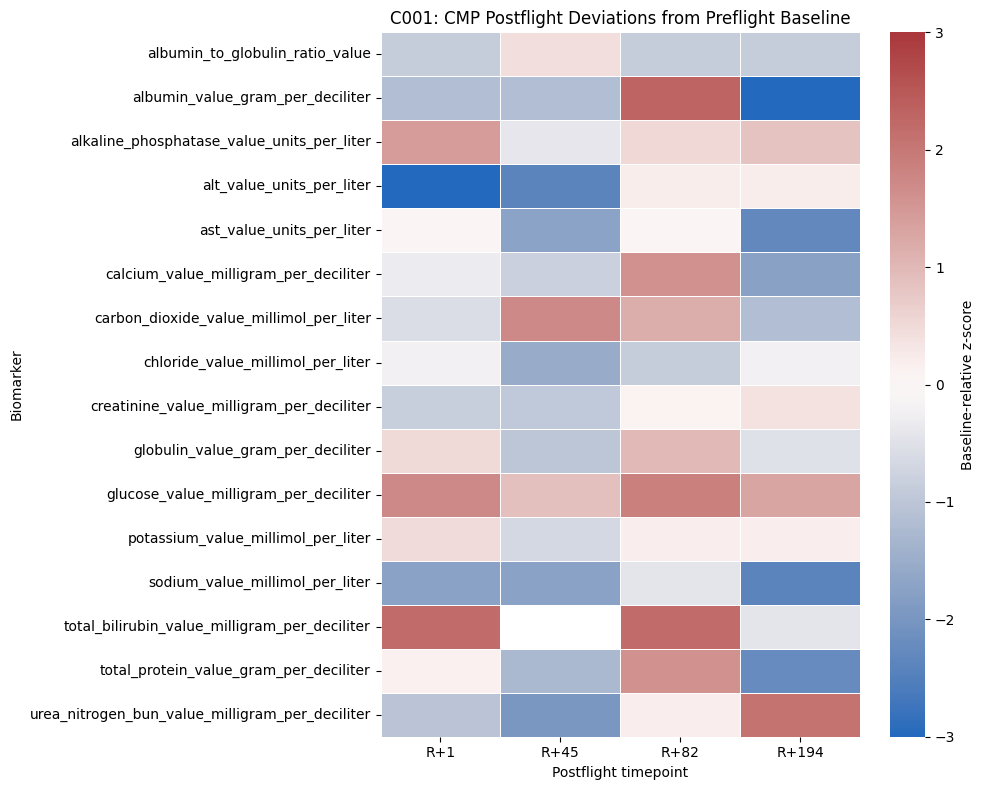

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Choose one participant to inspect first.
participant = "C001"

plot_df = cmp_review.loc[
    cmp_review["SUBJECT_ID"].eq(participant)
].copy()

# Arrange timepoints in chronological order.
time_order = ["R+1", "R+45", "R+82", "R+194"]

heatmap_data = plot_df.pivot(
    index="ANALYTE",
    columns="TEST_DATE",
    values="z_score"
).reindex(columns=time_order)

plt.figure(figsize=(10, 8))

sns.heatmap(
    heatmap_data,
    cmap="vlag",
    center=0,
    vmin=-3,
    vmax=3,
    mask=heatmap_data.isna(),
    linewidths=0.5,
    cbar_kws={"label": "Baseline-relative z-score"}
)

plt.title(f"{participant}: CMP Postflight Deviations from Preflight Baseline")
plt.xlabel("Postflight timepoint")
plt.ylabel("Biomarker")
plt.tight_layout()
plt.show()

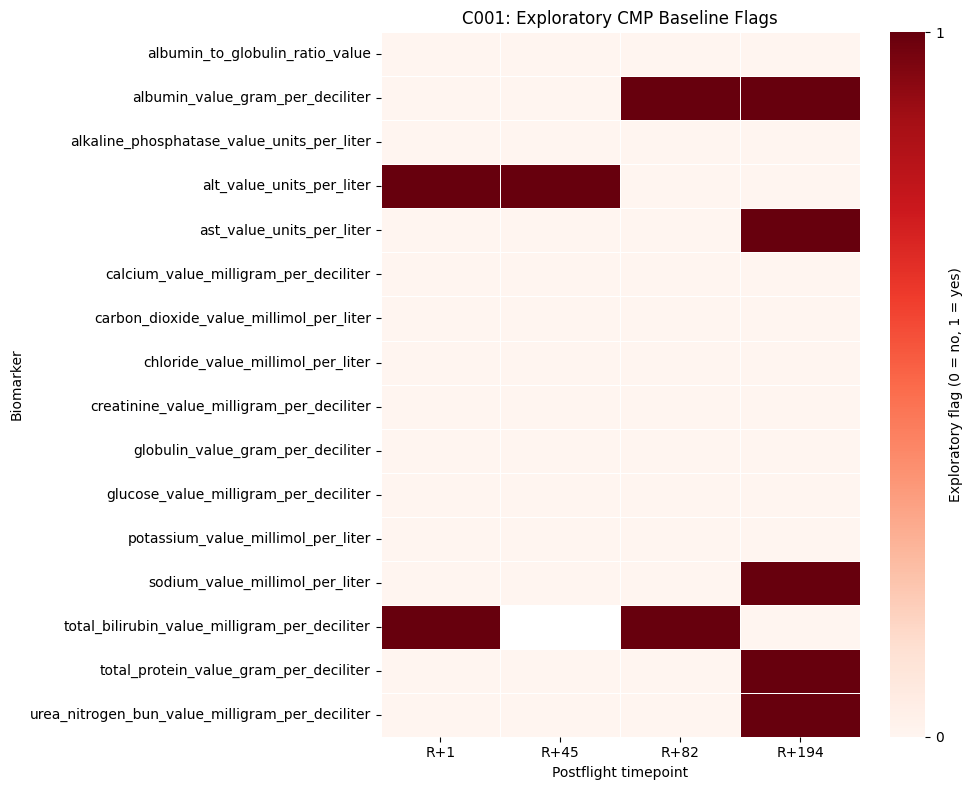

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

participant = "C001"

plot_df = cmp_review.loc[
    cmp_review["SUBJECT_ID"].eq(participant)
].copy()

time_order = ["R+1", "R+45", "R+82", "R+194"]

flag_data = plot_df.pivot(
    index="ANALYTE",
    columns="TEST_DATE",
    values="exploratory_flag"
).reindex(columns=time_order)

# True = flagged, False = not flagged, NA = unscored.
flag_numeric = flag_data.astype("float")

plt.figure(figsize=(10, 8))

sns.heatmap(
    flag_numeric,
    cmap="Reds",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    mask=flag_numeric.isna(),
    cbar_kws={"ticks": [0, 1], "label": "Exploratory flag (0 = no, 1 = yes)"}
)

plt.title(f"{participant}: Exploratory CMP Baseline Flags")
plt.xlabel("Postflight timepoint")
plt.ylabel("Biomarker")
plt.tight_layout()
plt.show()

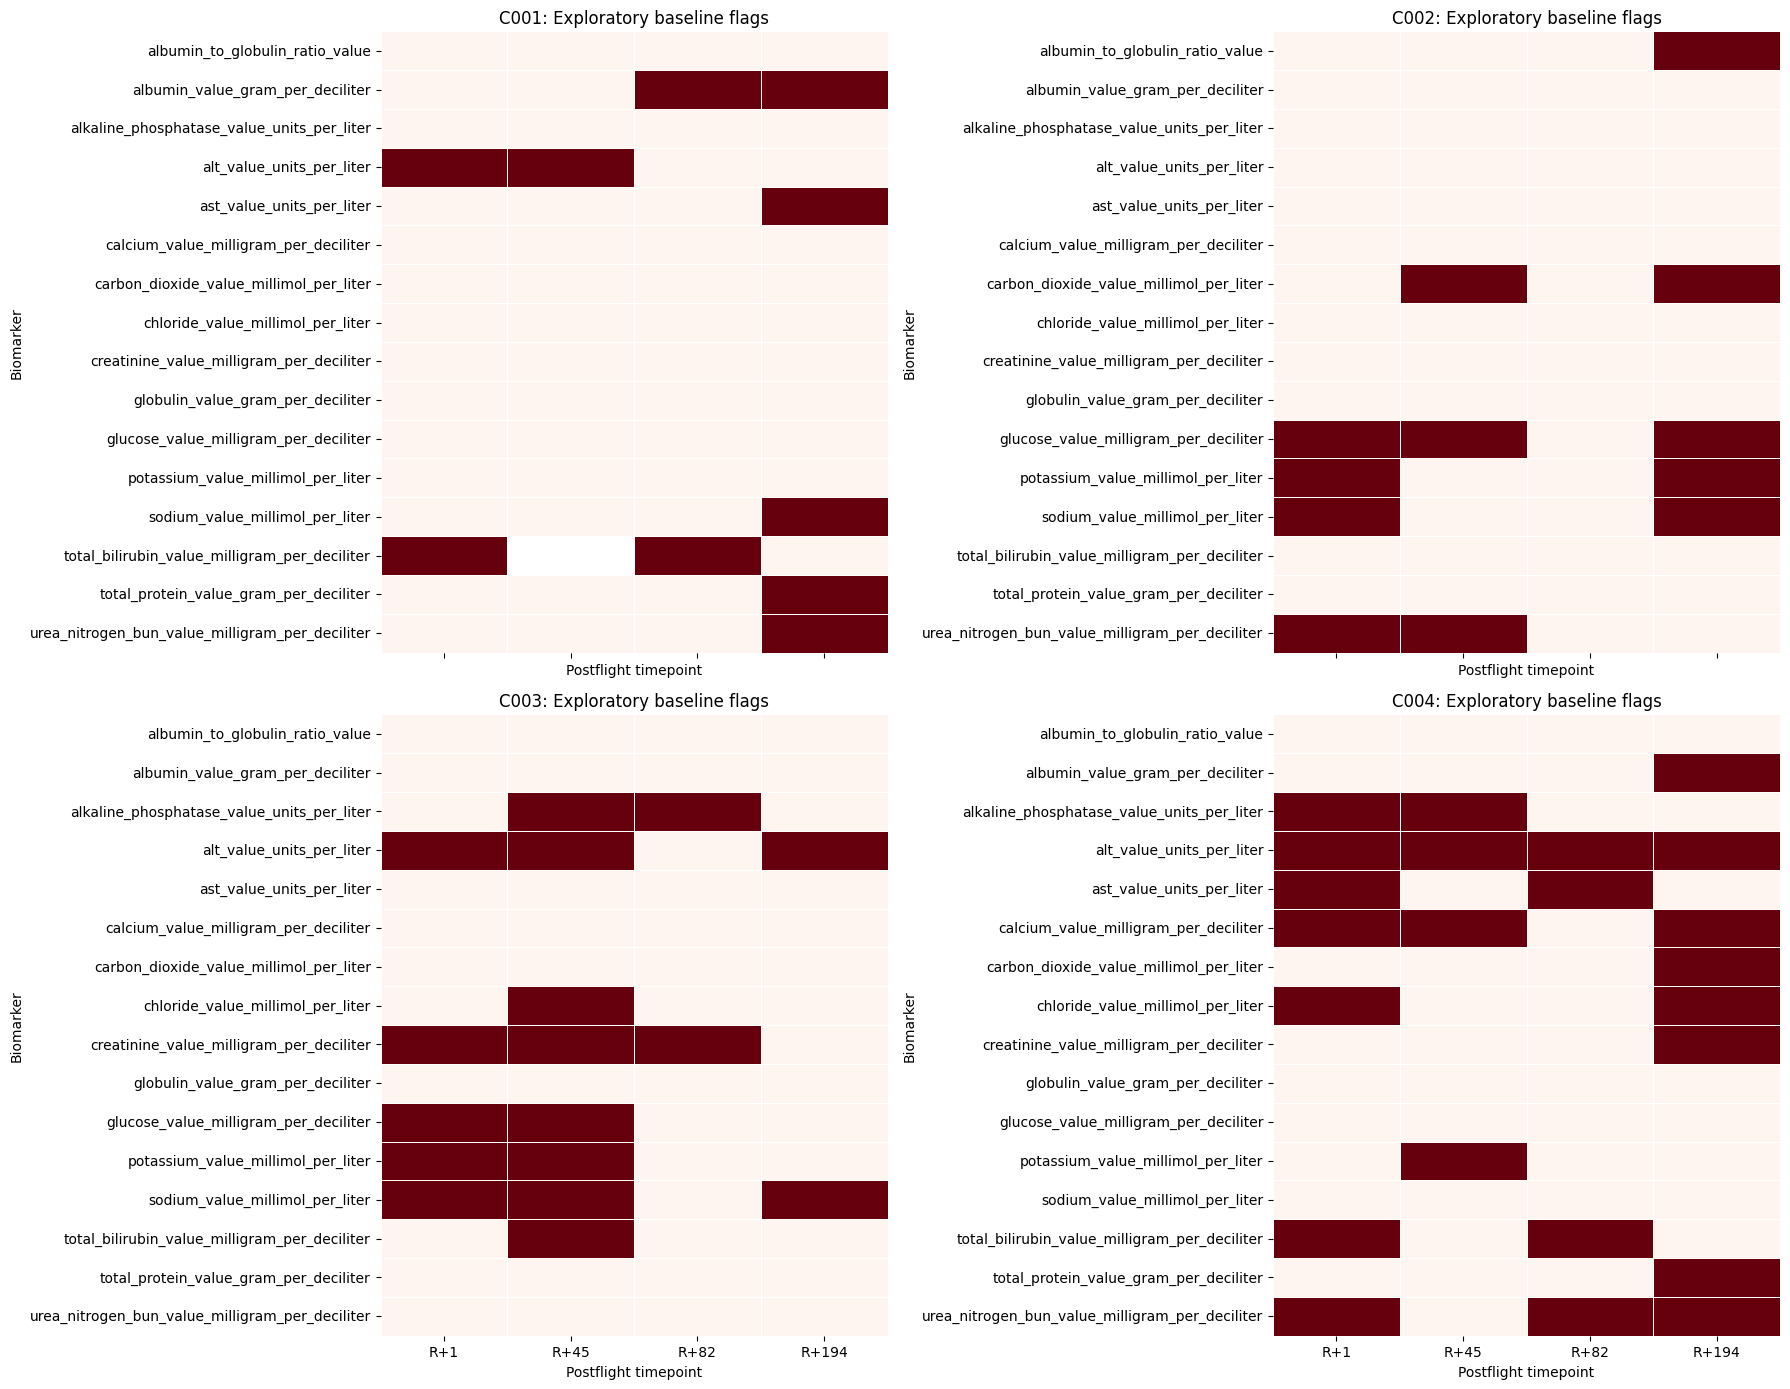

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

participants = ["C001", "C002", "C003", "C004"]
time_order = ["R+1", "R+45", "R+82", "R+194"]

fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 14),
    sharex=True
)

for participant, ax in zip(participants, axes.flat):
    plot_df = cmp_review.loc[
        cmp_review["SUBJECT_ID"].eq(participant)
    ].copy()

    flag_data = plot_df.pivot(
        index="ANALYTE",
        columns="TEST_DATE",
        values="exploratory_flag"
    ).reindex(columns=time_order)

    flag_numeric = flag_data.astype(float)

    sns.heatmap(
        flag_numeric,
        cmap="Reds",
        vmin=0,
        vmax=1,
        mask=flag_numeric.isna(),
        linewidths=0.4,
        cbar=False,
        ax=ax
    )

    ax.set_title(f"{participant}: Exploratory baseline flags")
    ax.set_xlabel("Postflight timepoint")
    ax.set_ylabel("Biomarker")

plt.tight_layout()
plt.show()

In [ ]:
participant_summary = (
    cmp_review.groupby("SUBJECT_ID")
    .agg(
        postflight_rows=("ANALYTE", "size"),
        scored_measurements=("z_score", "count"),
        baseline_flags=("exploratory_flag", "sum"),
        reference_deviations=("reference_deviation", "sum")
    )
)

participant_summary["baseline_flag_rate_pct"] = (
    participant_summary["baseline_flags"]
    / participant_summary["scored_measurements"]
    * 100
).round(1)

display(participant_summary)

,postflight_rows,scored_measurements,baseline_flags,reference_deviations,baseline_flag_rate_pct
SUBJECT_ID,,,,,
C001,64,63,10,1,15.9
C002,64,64,12,1,18.8
C003,64,64,17,5,26.6
C004,64,64,23,6,35.9


In [ ]:
from google.colab import files

cmp_analysis.to_csv("cmp_cleaned.csv", index=False)
files.download("cmp_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion — CMP Exploratory Data Analysis and Cleaning

The Comprehensive Metabolic Panel (CMP) dataset was explored, validated, and prepared for integration into the AstroHealth astronaut health-monitoring project. The analysis focused on data quality, participant-specific preflight baselines, postflight biomarker deviations, and comparisons with the reference ranges supplied in the dataset.

### 1. Data Inspection and Quality Assessment
- Inspected the dataset structure, consisting of 28 samples from four participants (C001–C004) across seven mission-relative timepoints.
- Parsed sample identifiers to extract participant IDs, sample type, and mission-relative timepoints.
- Verified that all sample identifiers were successfully parsed, with no duplicate samples identified.
- Examined missing values and the availability of biomarker measurements.

### 2. Data Cleaning and Feature Selection
- Created a separate analysis DataFrame to preserve the original working dataset.
- Excluded race-labelled estimated glomerular filtration rate (eGFR) features and the sparsely populated blood urea nitrogen-to-creatinine ratio features from the current baseline-scoring analysis.
- Standardized the ALT and AST reference-range column names for consistency.
- Identified one missing postflight total bilirubin measurement, which was retained as missing rather than imputed.

### 3. Preflight Baseline Analysis
- Defined L-92, L-44, and L-3 as the preflight baseline timepoints.
- Calculated participant-specific baseline means and standard deviations for 16 retained CMP biomarkers.
- Verified that all retained participant–biomarker combinations had three available preflight measurements and that no baseline standard deviations were exactly zero.

### 4. Postflight Deviation Scoring
- Evaluated postflight measurements at R+1, R+45, R+82, and R+194 relative to each participant's corresponding preflight baseline.
- Calculated baseline-relative z-scores to quantify the direction and magnitude of deviations.
- Applied an exploratory threshold of |z| > 2 to identify measurements for further review.
- Addressed floating-point precision at the threshold boundary to ensure consistent flagging.

### 5. Reference-Range Comparison
- Compared postflight biomarker measurements against the lower and upper reference limits supplied in the dataset.
- Classified measurements as below, within, or above the supplied reference range, while preserving missing or unavailable results as unscored.
- Kept personal-baseline deviations separate from reference-range deviations because the two measures represent different types of information.

### 6. Visualization and Summary Analysis
- Generated baseline-relative z-score heatmaps to examine the direction and magnitude of postflight changes.
- Created exploratory flag heatmaps for individual participants and across all four participants.
- Summarized baseline flags and reference-range deviations by participant and across postflight timepoints.
- Categorized measurements into baseline-flag-only, reference-range-deviation-only, both-signal, neither-signal, and missing/unscored groups.

### 7. Key Results
- **Samples analysed:** 28.
- **Participants:** 4.
- **Mission-relative timepoints:** 7.
- **CMP biomarkers retained for baseline scoring:** 16.
- **Postflight measurement rows:** 256.
- **Exploratory baseline flags after threshold correction:** 62.
- **Measurements above the supplied reference range:** 7.
- **Measurements below the supplied reference range:** 6.
- **Missing postflight measurement:** 1.

### 8. Limitations and Next Steps
The analysis is exploratory and is limited by the small cohort size and the use of only three preflight measurements to estimate each participant's baseline. The |z| > 2 threshold is an analytical rule, not a clinically validated decision threshold. The reference limits were taken from the supplied dataset, and their provenance and applicability have not been independently verified. The findings do not establish a diagnosis or demonstrate that spaceflight caused any observed change.

The cleaned CMP analysis data will be exported for integration with the cleaned Complete Blood Count (CBC) dataset. The subsequent unified biomarker pipeline will standardize both panels into a common long-format structure, preserve biomarker-specific units and reference limits, reproduce participant-specific baseline scoring, and prepare consistent analysis outputs for the AstroHealth dashboard.

**Overall conclusion:** CMP data inspection, cleaning decisions, baseline-relative scoring, reference-range comparison, and exploratory visualization have been completed. The resulting dataset and documented limitations provide the foundation for the next stage: developing a reproducible unified CBC–CMP analysis pipeline.
